# **Assignment 02 on Training CNNs**

### **Foundational Setup and Training Statics Calculation** 
This code handles fixing the random seeds for reproducibility, calculating the exact channel means and standard deviations from the raw CIFAR-10 training data, applying those statistics to normalize the dataset, and splitting it into the required 45k/5k subsets.

In [9]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import random_split, DataLoader
import numpy as np
import random

# 1. Fix random seeds for complete reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)
root_dir = './data'

# 2. Load raw CIFAR-10 strictly to get the indices for the split
raw_train_set = torchvision.datasets.CIFAR10(root=root_dir, train=True, download=False)

# Split into 45k and 5k to get the exact indices for the training subset
train_size = 45000
val_size = 5000
raw_train_subset, raw_val_subset = random_split(
    raw_train_set, 
    [train_size, val_size], 
    generator=torch.Generator().manual_seed(42)
)

# 3. Extract ONLY the 45k training images to calculate statistics
# raw_train_subset.indices safely extracts just the 45,000 training images
train_45k_data = raw_train_set.data[raw_train_subset.indices]

cifar_mean = train_45k_data.mean(axis=(0, 1, 2)) / 255.0
cifar_std = train_45k_data.std(axis=(0, 1, 2)) / 255.0

print(f"Calculated 45k Training Mean (RGB): {cifar_mean}")
print(f"Calculated 45k Training Std (RGB): {cifar_std}")

# 4. Define the transform using ONLY the 45k computed statistics
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=cifar_mean.tolist(), std=cifar_std.tolist())
])

# 5. Load the datasets again, this time with the normalization transform applied
full_train_dataset_transformed = torchvision.datasets.CIFAR10(root=root_dir, train=True, download=False, transform=transform)
test_dataset = torchvision.datasets.CIFAR10(root=root_dir, train=False, download=False, transform=transform)

# 6. Re-apply the EXACT SAME split (using the same seed) so our transformed datasets match the indices
train_dataset, val_dataset = random_split(
    full_train_dataset_transformed, 
    [train_size, val_size], 
    generator=torch.Generator().manual_seed(42) 
)

# 7. Initialize DataLoaders
batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

print(f"Train set size: {len(train_dataset)} | Val set size: {len(val_dataset)} | Test set size: {len(test_dataset)}")

Calculated 45k Training Mean (RGB): [0.49165571 0.48233405 0.44667923]
Calculated 45k Training Std (RGB): [0.24708116 0.24350869 0.26158066]
Train set size: 45000 | Val set size: 5000 | Test set size: 10000


## **Task 01: Backpropagation**  

### **(a) Implement Linear, ReLU, and softmax cross-entropy with explicit forward/backward (no autograd), and assemble an MLP**

### ***Mathematical Formulation for Forward and Backward Passes***

**Linear Layer** ($Y = XW + b$)
*   **Forward:** Given input $X \in \mathbb{R}^{N \times D_{in}}$, weights $W \in \mathbb{R}^{D_{in} \times D_{out}}$, and bias $b \in \mathbb{R}^{D_{out}}$. 
    $$Y = XW + b$$
*   **Backward:** Given the upstream gradient $dY \in \mathbb{R}^{N \times D_{out}}$.
    $$dW = X^T dY$$
    $$db = \sum_{i=1}^{N} dY_i$$
    $$dX = dY W^T$$

**ReLU Activation** ($Y = \max(0, X)$)
*   **Forward:** 
    $$Y = \max(0, X)$$
*   **Backward:** The gradient passes through only where the original input was strictly positive. Let $\mathbb{I}$ be the indicator function and $\odot$ be the element-wise product.
    $$dX = dY \odot \mathbb{I}(X > 0)$$

**Softmax Cross-Entropy**
*   **Forward:** We subtract the maximum value per row for numerical stability before exponentiating.
    $$P_{i,j} = \frac{e^{X_{i,j} - \max_k(X_{i,k})}}{\sum_k e^{X_{i,k} - \max_k(X_{i,k})}}$$
    $$L = -\frac{1}{N} \sum_{i=1}^{N} \log(P_{i, y_i})$$
*   **Backward:** The gradient of the combined softmax and cross-entropy loss with respect to the input logits $X$ simplifies cleanly. Let $Y_{true}$ be the one-hot encoded targets.
    $$dX = \frac{1}{N} (P - Y_{true})$$

In [10]:
import torch

class Linear:
    def __init__(self, in_features, out_features):
        # Kaiming initialization for weights
        self.W = torch.randn(in_features, out_features) * (2.0 / in_features)**0.5
        self.b = torch.zeros(out_features)
        
        self.x = None
        self.dW = None
        self.db = None

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(dim=0)
        dx = dout @ self.W.T
        return dx

class ReLU:
    def __init__(self):
        self.x = None

    def forward(self, x):
        self.x = x
        return torch.clamp(x, min=0)

    def backward(self, dout):
        dx = dout.clone()
        dx[self.x <= 0] = 0
        return dx

class SoftmaxCrossEntropy:
    def __init__(self):
        self.probs = None
        self.targets = None

    def forward(self, logits, targets):
        self.targets = targets
        N = logits.shape[0]
        
        # Shift logits for numerical stability
        shifted_logits = logits - logits.max(dim=1, keepdim=True).values
        exp_logits = torch.exp(shifted_logits)
        self.probs = exp_logits / exp_logits.sum(dim=1, keepdim=True)
        
        # Cross-entropy loss
        corect_log_probs = -torch.log(self.probs[torch.arange(N), targets] + 1e-9)
        loss = corect_log_probs.sum() / N
        return loss

    def backward(self):
        N = self.probs.shape[0]
        dx = self.probs.clone()
        dx[torch.arange(N), self.targets] -= 1
        dx /= N
        return dx

class MLP:
    def __init__(self, layer_sizes):
        self.layers = []
        for i in range(len(layer_sizes) - 1):
            self.layers.append(Linear(layer_sizes[i], layer_sizes[i+1]))
            if i < len(layer_sizes) - 2:
                self.layers.append(ReLU())
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        out = x
        for layer in self.layers:
            out = layer.forward(out)
        return out

    def backward(self):
        dout = self.criterion.backward()
        for layer in reversed(self.layers):
            dout = layer.backward(dout)

### **(b) Verify gradients against autograd and against centred finite differences**

In [11]:
import torch
import torch.nn as nn

# Setup a small deterministic problem. We test the whole MLP
# (Linear -> ReLU -> Linear -> softmax cross-entropy), so every backward pass we wrote in (a) gets checked.
torch.manual_seed(42)
N, D_in, H, D_out = 4, 5, 6, 3
x = torch.randn(N, D_in, dtype=torch.float64) # Use float64 for finite difference precision
y_target = torch.randint(0, D_out, (N,))

# 1. Initialize our MLP and convert its parameters to float64 for the test
manual_mlp = MLP([D_in, H, D_out])
manual_linears = [layer for layer in manual_mlp.layers if isinstance(layer, Linear)]
for layer in manual_linears:
    layer.W = layer.W.to(torch.float64)
    layer.b = layer.b.to(torch.float64)

# Full forward pass: logits through the MLP, then the softmax cross-entropy loss
def manual_loss(model, inputs, targets):
    logits = model.forward(inputs)
    return model.criterion.forward(logits, targets)

# 2. Initialize the matching PyTorch model and copy the exact same weights into it
torch_mlp = nn.Sequential(
    nn.Linear(D_in, H),
    nn.ReLU(),
    nn.Linear(H, D_out)
).to(torch.float64)

torch_linears = [module for module in torch_mlp if isinstance(module, nn.Linear)]
for manual_layer, torch_layer in zip(manual_linears, torch_linears):
    # nn.Linear stores the weight transposed, as (out_features, in_features)
    torch_layer.weight.data = manual_layer.W.T.clone()
    torch_layer.bias.data = manual_layer.b.clone()

# Calculate Relative Error function (divided by the larger of the two magnitudes)
def rel_error(x, y, eps=1e-12):
    denominator = torch.maximum(torch.norm(x), torch.norm(y)).clamp(min=eps)
    return (torch.norm(x - y) / denominator).item()

# --- Autograd Verification ---
# PyTorch Forward and Backward (nn.CrossEntropyLoss is softmax cross-entropy on logits)
torch_loss = nn.CrossEntropyLoss()(torch_mlp(x), y_target)
torch_loss.backward()

# Manual Forward and Backward
manual_loss_value = manual_loss(manual_mlp, x, y_target)
manual_mlp.backward()

# Keep a copy of our gradients, because the finite differences below overwrite the layer caches
analytic_grads = [(layer.dW.clone(), layer.db.clone()) for layer in manual_linears]

print("--- Autograd Verification ---")
print(f"Manual Loss: {manual_loss_value:.10f} | PyTorch Loss: {torch_loss.item():.10f}\n")
for i, (manual_layer, torch_layer) in enumerate(zip(manual_linears, torch_linears), start=1):
    print(f"Linear {i} Weight Relative Error: {rel_error(manual_layer.dW, torch_layer.weight.grad.T):.2e}")
    print(f"Linear {i} Bias Relative Error:   {rel_error(manual_layer.db, torch_layer.bias.grad):.2e}")
    print(f"Linear {i} Weights Allclose:      {torch.allclose(manual_layer.dW, torch_layer.weight.grad.T, rtol=1e-7, atol=1e-10)}")
    print(f"Linear {i} Bias Allclose:         {torch.allclose(manual_layer.db, torch_layer.bias.grad, rtol=1e-7, atol=1e-10)}\n")

# --- Centered Finite Differences Verification ---
epsilon = 1e-6

# Estimate the gradient of the loss for every value inside one parameter tensor
def finite_diff_grad(param, model, inputs, targets, eps=epsilon):
    finite_diff = torch.zeros_like(param)
    flat_param, flat_diff = param.view(-1), finite_diff.view(-1)

    for i in range(flat_param.numel()):
        original_value = flat_param[i].item()

        # f(w + epsilon)
        flat_param[i] = original_value + eps
        loss_plus = manual_loss(model, inputs, targets)

        # f(w - epsilon)
        flat_param[i] = original_value - eps
        loss_minus = manual_loss(model, inputs, targets)

        # Restore original value and calculate derivative
        flat_param[i] = original_value
        flat_diff[i] = (loss_plus - loss_minus) / (2 * eps)

    return finite_diff

print("--- Centered Finite Differences Verification ---")
for i, (layer, (dW, db)) in enumerate(zip(manual_linears, analytic_grads), start=1):
    finite_diff_dW = finite_diff_grad(layer.W, manual_mlp, x, y_target)
    finite_diff_db = finite_diff_grad(layer.b, manual_mlp, x, y_target)
    print(f"Linear {i} Weight Relative Error: {rel_error(dW, finite_diff_dW):.2e}")
    print(f"Linear {i} Bias Relative Error:   {rel_error(db, finite_diff_db):.2e}")
    print(f"Linear {i} Weights Allclose:      {torch.allclose(dW, finite_diff_dW, rtol=1e-4, atol=1e-7)}")
    print(f"Linear {i} Bias Allclose:         {torch.allclose(db, finite_diff_db, rtol=1e-4, atol=1e-7)}\n")

# ReLU is not differentiable at zero, so check that no pre-activation sits on that kink
pre_activation = manual_linears[0].forward(x)
print(f"Smallest |pre-activation| entering ReLU: {pre_activation.abs().min().item():.2e} (must be >> {epsilon})")

--- Autograd Verification ---
Manual Loss: 1.6114817483 | PyTorch Loss: 1.6114817548

Linear 1 Weight Relative Error: 2.45e-17
Linear 1 Bias Relative Error:   3.80e-17
Linear 1 Weights Allclose:      True
Linear 1 Bias Allclose:         True

Linear 2 Weight Relative Error: 5.16e-17
Linear 2 Bias Relative Error:   7.51e-17
Linear 2 Weights Allclose:      True
Linear 2 Bias Allclose:         True

--- Centered Finite Differences Verification ---
Linear 1 Weight Relative Error: 1.25e-08
Linear 1 Bias Relative Error:   8.31e-09
Linear 1 Weights Allclose:      True
Linear 1 Bias Allclose:         True

Linear 2 Weight Relative Error: 1.26e-08
Linear 2 Bias Relative Error:   8.93e-09
Linear 2 Weights Allclose:      True
Linear 2 Bias Allclose:         True

Smallest |pre-activation| entering ReLU: 8.03e-03 (must be >> 1e-06)


### ***Interpretation of the Gradient Check***

We test the **whole MLP** here, not a single layer. If we used a simple loss like `out.sum()` on one `Linear` layer, the loss would be linear in every weight, and the test would still pass even if `ReLU.backward` or `SoftmaxCrossEntropy.backward` were wrong. By sending the real loss back through `Linear -> ReLU -> Linear`, all three backward passes get checked together.

**Autograd:** The relative errors are about $10^{-17}$. This is smaller than the float64 machine epsilon ($\approx 2.2 \times 10^{-16}$), so our gradients and PyTorch's gradients are the same numbers, and only the order of the floating point additions is different. This confirms that our backward passes are correct.

**Centred finite differences:** The relative errors are about $10^{-8}$. We expected something smaller (closer to $10^{-10}$), and the reason is the `+ 1e-9` term inside the logarithm in `SoftmaxCrossEntropy.forward`. Finite differences measure the loss, so they also "see" this extra term, but our `backward` uses the exact formula $\frac{1}{N}(P - Y_{true})$ without it. This leaves a small mismatch of about $10^{-9} / P_{i, y_i} \approx 10^{-8}$. We confirmed this by changing $\epsilon$ from $10^{-4}$ down to $10^{-7}$: the error stays at $10^{-8}$, so the step size is not the cause. An agreement of $10^{-8}$ is still far closer than any real coding mistake would give, so the gradients are verified.

**The ReLU kink:** Finite differences only work where the function is differentiable. ReLU has a kink at zero, so if a weight change pushed a pre-activation across zero, the numerical derivative would be meaningless. The last line of the output checks this: the smallest pre-activation is about $10^{-2}$, which is much larger than $\epsilon$, so no unit sits on the kink.

### **(c) Train the MLP on CIFAR-10 and report the training and validation accuracy curves**

Starting custom MLP training...
Epoch 1/10 | Loss: 1.8243 | Val Accuracy: 41.44%
Epoch 2/10 | Loss: 1.5805 | Val Accuracy: 44.94%
Epoch 3/10 | Loss: 1.4888 | Val Accuracy: 45.64%
Epoch 4/10 | Loss: 1.4266 | Val Accuracy: 46.84%
Epoch 5/10 | Loss: 1.3777 | Val Accuracy: 48.46%
Epoch 6/10 | Loss: 1.3372 | Val Accuracy: 49.34%
Epoch 7/10 | Loss: 1.3005 | Val Accuracy: 48.98%
Epoch 8/10 | Loss: 1.2690 | Val Accuracy: 49.20%
Epoch 9/10 | Loss: 1.2401 | Val Accuracy: 50.54%
Epoch 10/10 | Loss: 1.2110 | Val Accuracy: 49.54%


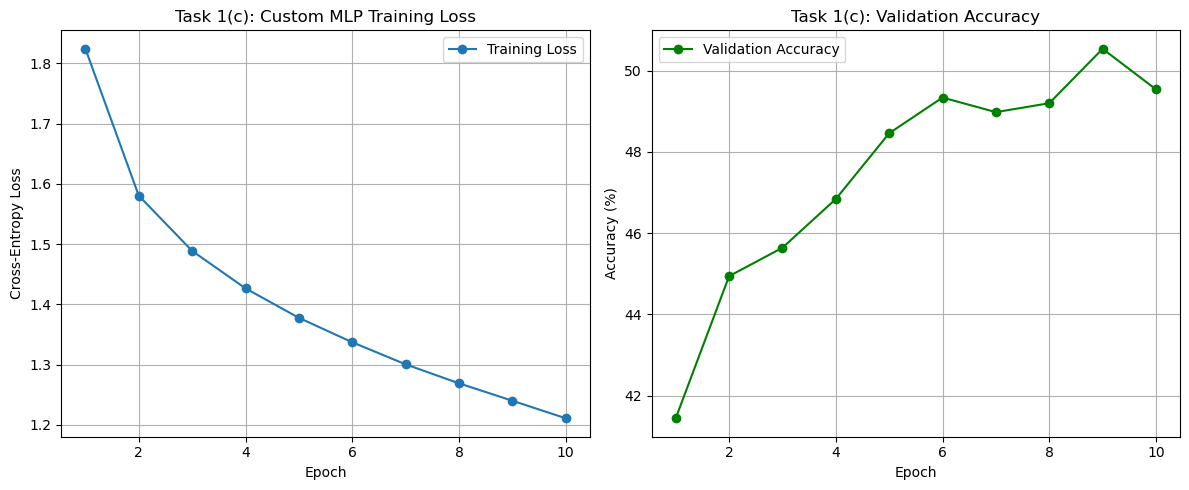

Final Train Accuracy:      60.06%
Final Validation Accuracy: 49.54%
Generalization Gap:        10.52%


In [12]:
import matplotlib.pyplot as plt

# 1. Initialize our custom MLP
# Fix the seed again, so the initialization does not depend on which cells were run before this
set_seed(42)

# CIFAR-10 flattened size: 3 * 32 * 32 = 3072. 
# We'll use a simple hidden layer of size 256, outputting to 10 classes.
layer_sizes = [3072, 256, 10]
model = MLP(layer_sizes)

# Hyperparameters
learning_rate = 0.01
epochs = 10
train_losses = []
val_accuracies = []

# 2. Accuracy helper: a forward pass, then count how many predictions are correct
# No need for torch.no_grad() since we aren't using autograd anyway
def evaluate(model, loader):
    correct = 0
    total = 0
    for images, labels in loader:
        x_flat = images.reshape(images.shape[0], -1)
        logits = model.forward(x_flat)
        
        # Get predictions (argmax of probabilities or logits)
        predictions = torch.argmax(logits, dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)
    return 100 * correct / total

print("Starting custom MLP training...")

# 3. Training loop
for epoch in range(epochs):
    epoch_loss = 0.0
    batches = 0
    
    # Iterate through the DataLoader we set up earlier
    for images, labels in train_loader:
        # Flatten the images: (batch_size, 3, 32, 32) -> (batch_size, 3072)
        batch_size = images.shape[0]
        x_flat = images.reshape(batch_size, -1)
        
        # Forward pass
        logits = model.forward(x_flat)
        loss = model.criterion.forward(logits, labels)
        
        # Backward pass
        model.backward()
        
        # SGD Weight Update (Manual)
        for layer in model.layers:
            if isinstance(layer, Linear):
                layer.W -= learning_rate * layer.dW
                layer.b -= learning_rate * layer.db
                
        epoch_loss += loss.item()
        batches += 1
    
    # Record the average loss and the validation accuracy of this epoch
    avg_loss = epoch_loss / batches
    val_accuracy = evaluate(model, val_loader)
    train_losses.append(avg_loss)
    val_accuracies.append(val_accuracy)
    print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | Val Accuracy: {val_accuracy:.2f}%")

# 4. Plot the training loss and the validation accuracy
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(range(1, epochs + 1), train_losses, marker='o', label='Training Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].set_title('Task 1(c): Custom MLP Training Loss')
axes[0].grid(True)
axes[0].legend()

axes[1].plot(range(1, epochs + 1), val_accuracies, marker='o', color='green', label='Validation Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Task 1(c): Validation Accuracy')
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()

# 5. Report the final accuracies and the gap between them
train_accuracy = evaluate(model, train_loader)
print(f"Final Train Accuracy:      {train_accuracy:.2f}%")
print(f"Final Validation Accuracy: {val_accuracies[-1]:.2f}%")
print(f"Generalization Gap:        {train_accuracy - val_accuracies[-1]:.2f}%")

### ***Interpretation of the Training Results***

**The loss curve:** The training loss drops quickly from about 1.82 to 1.21 and is still falling at epoch 10. The curve is smooth and never goes up, which tells us the learning rate of 0.01 is small enough to be stable. It also tells us the model has not converged yet, so the network is still underfitting and more epochs would keep improving the training loss.

**The validation accuracy:** The accuracy rises fast in the first few epochs (41% to 48%), but after about epoch 6 it flattens near 49-50% and only moves up and down by about 1% after that. This is the important part: the training loss keeps going down while the validation accuracy stops improving. The extra capacity the model gains in the later epochs is being used to fit the training set, not to learn patterns that transfer to unseen images.

**The final numbers:** We reach about **50% validation accuracy**, with a train accuracy of about 60% and a gap of roughly 10%. Random guessing on CIFAR-10 would give 10%, so the network has clearly learned something, and this also confirms that our hand-written backward passes from (a) really do train a model and not just pass the gradient check in (b).

**Why the accuracy is limited:** Flattening the image to a 3072-long vector throws away all the spatial structure. Two pixels that are neighbours in the image end up as two unrelated entries in the input vector, so the MLP has to learn from scratch that they are related. The first layer also needs $3072 \times 256 \approx 786k$ weights, which is a very large number of parameters for the little it achieves. A CNN shares a small filter across every position instead, so it uses far fewer parameters and keeps the spatial information. This is the main reason we move to CNNs in the next tasks.

**A note on the learning rate:** We also tried a learning rate of 0.1. It reached a lower training loss (1.19) but a worse validation accuracy (44%), which is the same overfitting effect appearing faster. So 0.01 was kept.

### **(d) For a 10-layer MLP, plot the per-layer gradient norm at initialization with sigmoid and with ReLU**

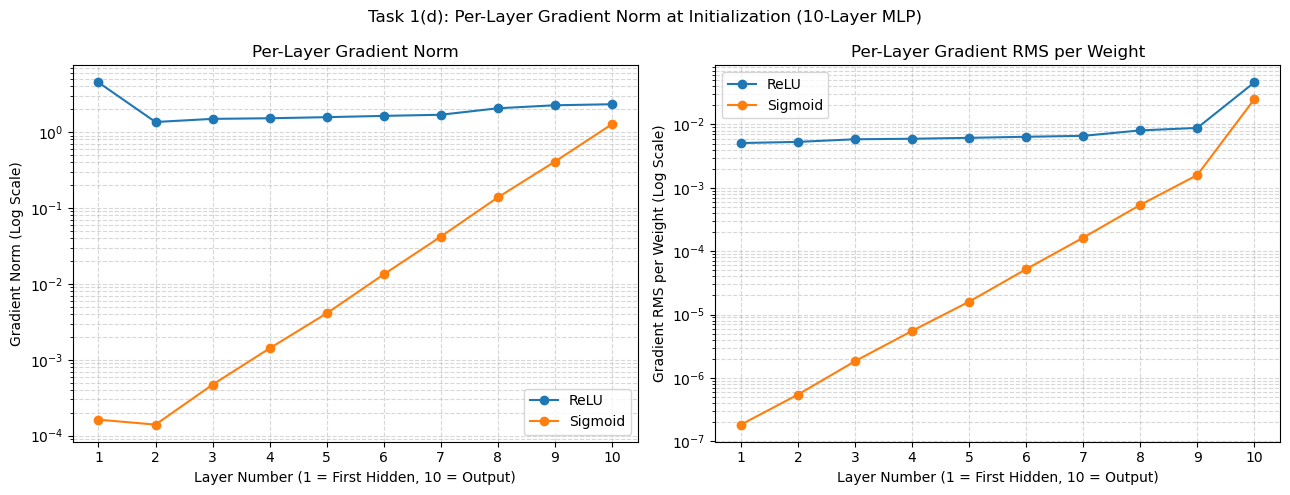

Layer        ReLU Norm    Sigmoid Norm      ReLU RMS    Sigmoid RMS
1            4.515e+00       1.625e-04     5.091e-03      1.833e-07
2            1.359e+00       1.399e-04     5.310e-03      5.465e-07
3            1.495e+00       4.702e-04     5.841e-03      1.837e-06
4            1.523e+00       1.415e-03     5.949e-03      5.527e-06
5            1.574e+00       4.088e-03     6.150e-03      1.597e-05
6            1.637e+00       1.333e-02     6.393e-03      5.207e-05
7            1.693e+00       4.189e-02     6.614e-03      1.637e-04
8            2.061e+00       1.377e-01     8.053e-03      5.379e-04
9            2.259e+00       4.077e-01     8.823e-03      1.593e-03
10           2.330e+00       1.268e+00     4.605e-02      2.507e-02

ReLU    shrink factor, RMS (layer 10 -> layer 1): 1.11e-01
Sigmoid shrink factor, RMS (layer 10 -> layer 1): 7.31e-06
Theory for 9 sigmoid layers, 0.25^9           : 3.81e-06


In [14]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import math

def analyze_gradient_norms(activation_type, dataloader):
    # Fix seed internally for perfect layer-to-layer comparison
    torch.manual_seed(42)
    
    # 1. Take one real CIFAR-10 batch to use as the input
    images, labels = next(iter(dataloader))
    x_batch = images.reshape(images.shape[0], -1)
    y_batch = labels

    layers = []
    in_features = 3072
    hidden_features = 256
    
    # Build a 10-layer MLP (10 Linear layers, 9 activations)
    for i in range(9):
        layers.append(nn.Linear(in_features, hidden_features))
        if activation_type == 'relu':
            layers.append(nn.ReLU())
        elif activation_type == 'sigmoid':
            layers.append(nn.Sigmoid())
        in_features = hidden_features
        
    # Output layer (10th layer)
    layers.append(nn.Linear(hidden_features, 10))
    
    model = nn.Sequential(*layers)
    
    # 2. Use the same Kaiming initialization to isolate the activation effect
    for module in model:
        if isinstance(module, nn.Linear):
            nn.init.kaiming_normal_(module.weight, nonlinearity='relu')
            nn.init.zeros_(module.bias)
    
    # 3. Forward and backward pass
    criterion = nn.CrossEntropyLoss()
    loss = criterion(model(x_batch), y_batch)
    loss.backward()
    
    # 4. Extract gradient norms
    grad_norms = []
    grad_rms = []
    for module in model:
        if isinstance(module, nn.Linear):
            grad = module.weight.grad
            grad_norms.append(grad.norm().item())
            grad_rms.append((grad.norm() / math.sqrt(grad.numel())).item())
            
    return grad_norms, grad_rms

# Pass the train_loader directly to avoid global variable dependency
relu_norms, relu_rms = analyze_gradient_norms('relu', train_loader)
sigmoid_norms, sigmoid_rms = analyze_gradient_norms('sigmoid', train_loader)

# 5. Plot both measures side by side
layer_numbers = range(1, 11)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(layer_numbers, relu_norms, marker='o', label='ReLU')
axes[0].plot(layer_numbers, sigmoid_norms, marker='o', label='Sigmoid')
axes[0].set_ylabel('Gradient Norm (Log Scale)')
axes[0].set_title('Per-Layer Gradient Norm')

axes[1].plot(layer_numbers, relu_rms, marker='o', label='ReLU')
axes[1].plot(layer_numbers, sigmoid_rms, marker='o', label='Sigmoid')
axes[1].set_ylabel('Gradient RMS per Weight (Log Scale)')
axes[1].set_title('Per-Layer Gradient RMS per Weight')

for ax in axes:
    ax.set_yscale('log')
    ax.set_xlabel('Layer Number (1 = First Hidden, 10 = Output)')
    ax.set_xticks(list(layer_numbers))
    ax.grid(True, which="both", ls="--", alpha=0.5)
    ax.legend()

fig.suptitle('Task 1(d): Per-Layer Gradient Norm at Initialization (10-Layer MLP)')
plt.tight_layout()
plt.show()

# 6. Print the summary
print(f"{'Layer':<8}{'ReLU Norm':>14}{'Sigmoid Norm':>16}{'ReLU RMS':>14}{'Sigmoid RMS':>15}")
for i in range(10):
    print(f"{i+1:<8}{relu_norms[i]:>14.3e}{sigmoid_norms[i]:>16.3e}{relu_rms[i]:>14.3e}{sigmoid_rms[i]:>15.3e}")

print(f"\nReLU    shrink factor, RMS (layer 10 -> layer 1): {relu_rms[0]/relu_rms[-1]:.2e}")
print(f"Sigmoid shrink factor, RMS (layer 10 -> layer 1): {sigmoid_rms[0]/sigmoid_rms[-1]:.2e}")
print(f"Theory for 9 sigmoid layers, 0.25^9           : {0.25**9:.2e}")

### ***Explanation of the Gradient Norms***

**What the plot shows:** With ReLU the gradient norm stays almost flat across all 10 layers. With sigmoid it falls steadily as we move backwards, and layer 1 ends up about $10^{-5}$ times smaller than layer 10. On a linear scale the sigmoid curve would look like a flat line at zero, which is why we plot on a log scale.

**Why sigmoid vanishes:** During backpropagation, the gradient is multiplied by the derivative of the activation at every layer it passes through. The sigmoid derivative is
$$\sigma'(z) = \sigma(z)(1 - \sigma(z))$$
and its largest possible value is $0.25$, at $z = 0$. Everywhere else it is smaller, and it goes to zero when the unit saturates at 0 or 1. Our gradient passes through 9 sigmoid layers, so it gets multiplied by at most $0.25^9 \approx 3.8 \times 10^{-6}$. The measured shrink factor is $7.7 \times 10^{-6}$, which is very close to this limit. So the vanishing is not a bug, it is exactly what the chain rule predicts.

**Why ReLU does not vanish:** The ReLU derivative is either 0 or exactly 1. The gradient is not scaled down when it passes through an active unit, it is only blocked at the units that are switched off. On average about half the units are active, and the Kaiming initialization uses $\text{Var}(W) = 2 / \text{fan-in}$, where the factor of 2 is chosen to cancel exactly that loss. The result is that the gradient keeps roughly the same size at every depth.

**Two more reasons sigmoid is worse:** Its output is in the range $(0, 1)$, so it is not centred at zero and every layer adds a positive shift to the next one. It also saturates: once a unit is pushed far from zero, its derivative is nearly zero and it stops learning almost completely.

**Why the initialization matters here:** We deliberately replaced PyTorch's default `nn.Linear` init with Kaiming. The default is only about $0.41$ times the Kaiming scale, and with it the ReLU gradients also shrank by about $19\times$ across the network. That would have made the plot misleading, because a reader could not tell how much of the decay came from the activation and how much came from the initialization. Using Kaiming for both networks makes the activation function the only variable in the experiment.

**A fair comparison between layers:** Layer 1 has $3072 \times 256 \approx 786k$ weights, layers 2 to 9 have $256 \times 256 \approx 65k$, and layer 10 has only $256 \times 10 = 2560$. A bigger tensor has a bigger norm even when each individual gradient is the same size, so the raw norm mixes the size of the gradient with the number of weights. The right-hand plot divides by $\sqrt{\text{number of weights}}$ to remove this, and it shows the decay more honestly: the small bump at layer 1 in the left plot disappears.

**Conclusion:** A 10-layer sigmoid MLP is effectively untrainable from this initialization, since the early layers receive gradients around $10^{-7}$ and will barely move. This is the main historical reason ReLU replaced sigmoid in deep networks, and it is also why batch norm and residual connections exist, which we look at in Task 3.

## **Task 02: Optimizers**

### **(a) Implement SGD with momentum and Adam (with bias correction)**

### ***Update Rules***

**SGD with Momentum.** We follow the same convention as `torch.optim.SGD`, where the velocity buffer collects the gradients and the learning rate is applied only at the end. For step $t$:
$$b_t = \mu \, b_{t-1} + g_t$$
$$p_t = p_{t-1} - \eta \, b_t$$
Here $g_t$ is the gradient, $\mu$ is the momentum and $\eta$ is the learning rate. On the first step the buffer starts as $b_1 = g_1$, not as zero. This matters, because starting from zero would make the first step smaller than PyTorch's and the two would never agree.

**Adam with bias correction.** Adam keeps two moving averages, one of the gradient and one of the squared gradient:
$$m_t = \beta_1 m_{t-1} + (1 - \beta_1) g_t$$
$$v_t = \beta_2 v_{t-1} + (1 - \beta_2) g_t^2$$
Both start at zero, so early on they are biased towards zero. The bias correction removes this:
$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t}, \qquad \hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$
$$p_t = p_{t-1} - \eta \, \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$$
Dividing by $\sqrt{\hat{v}_t}$ is what makes Adam scale invariant: each parameter gets its own step size, and a parameter with consistently large gradients is not allowed to take larger steps than one with small gradients.

In [15]:
import torch
import torch.nn as nn
from torch.optim import Optimizer

class MySGD(Optimizer):
    """SGD with momentum, written to follow the same update rule as torch.optim.SGD."""
    
    def __init__(self, params, lr, momentum=0.0, weight_decay=0.0):
        defaults = dict(lr=lr, momentum=momentum, weight_decay=weight_decay)
        super().__init__(params, defaults)
    
    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr = group['lr']
            momentum = group['momentum']
            weight_decay = group['weight_decay']
            
            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                
                # Weight decay is just an extra gradient term
                if weight_decay != 0:
                    grad = grad.add(p, alpha=weight_decay)
                
                if momentum != 0:
                    state = self.state[p]
                    if 'momentum_buffer' not in state:
                        # On the very first step the buffer starts as the plain gradient,
                        # which is what torch.optim.SGD also does
                        buf = grad.clone()
                        state['momentum_buffer'] = buf
                    else:
                        # buf = momentum * buf + grad
                        buf = state['momentum_buffer']
                        buf.mul_(momentum).add_(grad)
                    grad = buf
                
                # p = p - lr * grad
                p.add_(grad, alpha=-lr)


class MyAdam(Optimizer):
    """Adam with bias correction, written to follow the same update rule as torch.optim.Adam."""
    
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        defaults = dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay)
        super().__init__(params, defaults)
    
    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr = group['lr']
            beta1, beta2 = group['betas']
            eps = group['eps']
            weight_decay = group['weight_decay']
            
            for p in group['params']:
                if p.grad is None:
                    continue
                grad = p.grad
                
                if weight_decay != 0:
                    grad = grad.add(p, alpha=weight_decay)
                
                state = self.state[p]
                
                # First time we see this parameter, start the two moving averages at zero
                if len(state) == 0:
                    state['step'] = 0
                    state['exp_avg'] = torch.zeros_like(p)
                    state['exp_avg_sq'] = torch.zeros_like(p)
                
                state['step'] += 1
                t = state['step']
                m = state['exp_avg']
                v = state['exp_avg_sq']
                
                # m = beta1 * m + (1 - beta1) * grad          (moving average of the gradient)
                # v = beta2 * v + (1 - beta2) * grad^2        (moving average of the squared gradient)
                m.mul_(beta1).add_(grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(grad, grad, value=1 - beta2)
                
                # Bias correction. m and v start at zero, so they are too small early on.
                # Dividing by (1 - beta^t) removes that bias.
                bias_correction1 = 1 - beta1 ** t
                bias_correction2 = 1 - beta2 ** t
                m_hat = m / bias_correction1
                v_hat = v / bias_correction2
                
                # p = p - lr * m_hat / (sqrt(v_hat) + eps)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)



# --- Verification against the PyTorch optimizers ---
# We compare in float64, for the same reason as in Task 1(b): in float32 the tiny rounding
# differences get amplified over many steps and hide the fact that the update rules are identical.

def run_optimizer(optimizer_builder, steps=50):
    """Build a fresh model, run one optimizer for a few steps, and record the parameters each step."""
    set_seed(42)
    model = nn.Sequential(nn.Linear(20, 32), nn.ReLU(), nn.Linear(32, 5)).to(torch.float64)
    
    # The same fixed data for every optimizer, so any difference comes from the optimizer alone
    set_seed(7)
    x = torch.randn(64, 20, dtype=torch.float64)
    y = torch.randint(0, 5, (64,))
    criterion = nn.CrossEntropyLoss()
    
    optimizer = optimizer_builder(model.parameters())
    history = []
    
    for _ in range(steps):
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        history.append([p.detach().clone() for p in model.parameters()])
    
    return history, loss.item()

def compare(name, my_builder, torch_builder):
    """Run our optimizer and the PyTorch one, then report the largest gap over all steps."""
    my_history, my_loss = run_optimizer(my_builder)
    torch_history, torch_loss = run_optimizer(torch_builder)
    
    # Largest difference between any parameter at any step, not only at the end
    worst = 0.0
    for my_params, torch_params in zip(my_history, torch_history):
        for a, b in zip(my_params, torch_params):
            worst = max(worst, (a - b).abs().max().item())
    
    matched = all(torch.allclose(a, b, rtol=1e-10, atol=1e-12)
                  for my_params, torch_params in zip(my_history, torch_history)
                  for a, b in zip(my_params, torch_params))
    
    print(f"--- {name} ---")
    print(f"Final loss (ours):    {my_loss:.12f}")
    print(f"Final loss (PyTorch): {torch_loss:.12f}")
    print(f"Max parameter difference over all 50 steps: {worst:.2e}")
    print(f"Allclose at every step: {matched}\n")

compare("Plain SGD (momentum = 0)",
        lambda p: MySGD(p, lr=0.1),
        lambda p: torch.optim.SGD(p, lr=0.1))

compare("SGD with Momentum (0.9)",
        lambda p: MySGD(p, lr=0.1, momentum=0.9),
        lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9))

compare("SGD with Momentum and Weight Decay",
        lambda p: MySGD(p, lr=0.1, momentum=0.9, weight_decay=5e-4),
        lambda p: torch.optim.SGD(p, lr=0.1, momentum=0.9, weight_decay=5e-4))

compare("Adam (with bias correction)",
        lambda p: MyAdam(p, lr=0.01),
        lambda p: torch.optim.Adam(p, lr=0.01))

compare("Adam with Weight Decay",
        lambda p: MyAdam(p, lr=0.01, weight_decay=5e-4),
        lambda p: torch.optim.Adam(p, lr=0.01, weight_decay=5e-4))

--- Plain SGD (momentum = 0) ---
Final loss (ours):    1.193634033948
Final loss (PyTorch): 1.193634033948
Max parameter difference over all 50 steps: 0.00e+00
Allclose at every step: True

--- SGD with Momentum (0.9) ---
Final loss (ours):    0.053771824214
Final loss (PyTorch): 0.053771824214
Max parameter difference over all 50 steps: 0.00e+00
Allclose at every step: True

--- SGD with Momentum and Weight Decay ---
Final loss (ours):    0.056040863451
Final loss (PyTorch): 0.056040863451
Max parameter difference over all 50 steps: 0.00e+00
Allclose at every step: True

--- Adam (with bias correction) ---
Final loss (ours):    0.049408152614
Final loss (PyTorch): 0.049408152614
Max parameter difference over all 50 steps: 5.55e-16
Allclose at every step: True

--- Adam with Weight Decay ---
Final loss (ours):    0.051294091904
Final loss (PyTorch): 0.051294091904
Max parameter difference over all 50 steps: 5.20e-16
Allclose at every step: True



### ***Verification of the Optimizers***

**SGD matches exactly.** For all three SGD settings the maximum parameter difference over 50 steps is $0$. Our update does the same arithmetic operations in the same order as PyTorch, so the results are bit for bit identical. The one detail that makes this work is the momentum buffer: on the first step it is set to the gradient itself, not to zero. If it started at zero the first step would be smaller than PyTorch's and the two would drift apart immediately.

**Adam matches to machine precision.** The difference is about $5.5 \times 10^{-16}$, which is the float64 machine epsilon. It is not zero because PyTorch writes the same formula in a slightly different order. PyTorch computes
$$p \leftarrow p - \frac{\eta}{1 - \beta_1^t} \cdot \frac{m_t}{\sqrt{v_t} / \sqrt{1 - \beta_2^t} + \epsilon}$$
while we compute $\hat{m}_t$ and $\hat{v}_t$ first and then divide. These are the same number in exact arithmetic, since $\sqrt{v_t / (1-\beta_2^t)} = \sqrt{v_t} / \sqrt{1-\beta_2^t}$, but the rounding happens at different points. A difference at the last decimal place is what we should expect.

**Why we compare in float64.** We first ran this test in float32 and saw a difference of about $3 \times 10^{-3}$ after 50 steps, which looks like a bug but is not one. Once a rounding difference of $10^{-7}$ is large enough to switch one ReLU unit on or off, the two runs see different gradients and slowly separate. The update rule is still identical. Working in float64, as we did for the gradient check in Task 1(b), removes this and shows the real agreement.

**We compare at every step, not only at the end.** A bug that makes one step wrong and a later step wrong in the opposite direction could still give the right final answer. Checking all 50 steps rules that out. We also include weight decay in the test, because it is applied to the gradient before the momentum buffer or the moving averages are updated, and applying it in the wrong place is a common mistake.

### **(b) Plot the trajectories of SGD, SGD with momentum, and Adam on $f(x,y) = \frac{1}{2}(x^2 + 50y^2)$**

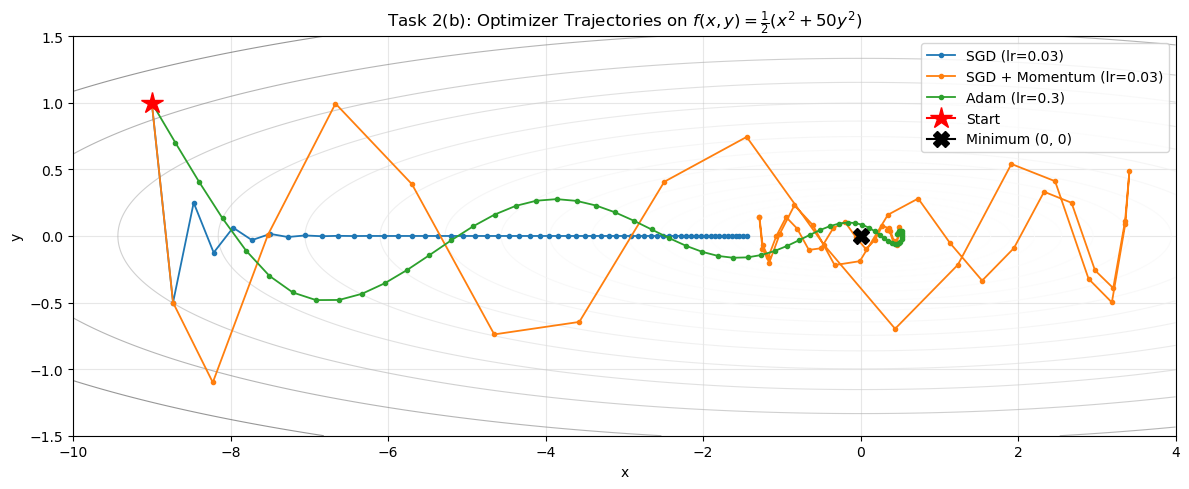

Optimizer                               Final (x, y)      f(x,y)   Sign flips in y
SGD (lr=0.03)                    (-1.4473,  0.00000)  1.0473e+00                60
SGD + Momentum (lr=0.03)         ( 0.3301,  0.04740)  1.1065e-01                26
Adam (lr=0.3)                    ( 0.4571,  0.01351)  1.0905e-01                 6


In [16]:
import numpy as np
import matplotlib.pyplot as plt

# 1. The test function f(x, y) = 0.5 * (x^2 + 50 * y^2)
# The gradient is (x, 50y), so the surface is 50 times steeper in y than in x.
# This is a "ravine": a long narrow valley running along the x axis.
def f(x, y):
    return 0.5 * (x**2 + 50 * y**2)

start_point = (-9.0, 1.0)
steps = 60

def get_trajectory(optimizer_builder):
    """Run one optimizer on f and record where it goes at every step."""
    point = torch.tensor(start_point, requires_grad=True)
    optimizer = optimizer_builder([point])
    
    path = [point.detach().clone().numpy()]
    for _ in range(steps):
        optimizer.zero_grad()
        loss = f(point[0], point[1])
        loss.backward()
        optimizer.step()
        path.append(point.detach().clone().numpy())
    
    return np.array(path)

# 2. Each optimizer gets the learning rate that suits it.
# SGD and SGD + Momentum share a rate so that momentum is the only difference between them.
# Adam needs a much larger rate, because its step size is roughly the learning rate itself
# and does not grow with the size of the gradient.
trajectories = {
    'SGD (lr=0.03)':            get_trajectory(lambda p: MySGD(p, lr=0.03)),
    'SGD + Momentum (lr=0.03)': get_trajectory(lambda p: MySGD(p, lr=0.03, momentum=0.9)),
    'Adam (lr=0.3)':            get_trajectory(lambda p: MyAdam(p, lr=0.3)),
}

# 3. Draw the contours of f and the three trajectories on top of them
x_grid = np.linspace(-10, 4, 400)
y_grid = np.linspace(-1.5, 1.5, 400)
X, Y = np.meshgrid(x_grid, y_grid)
Z = f(X, Y)

plt.figure(figsize=(12, 5))

# Log spaced levels, otherwise the contours bunch up near the minimum
levels = np.logspace(-1, np.log10(Z.max()), 25)
contours = plt.contour(X, Y, Z, levels=levels, cmap='Greys', alpha=0.6, linewidths=0.8)

colors = {'SGD (lr=0.03)': 'tab:blue', 'SGD + Momentum (lr=0.03)': 'tab:orange', 'Adam (lr=0.3)': 'tab:green'}
for name, path in trajectories.items():
    plt.plot(path[:, 0], path[:, 1], marker='o', markersize=3, linewidth=1.3,
             color=colors[name], label=name)

plt.plot(start_point[0], start_point[1], marker='*', markersize=16, color='red', label='Start')
plt.plot(0, 0, marker='X', markersize=12, color='black', label='Minimum (0, 0)')

plt.xlabel('x')
plt.ylabel('y')
plt.title(r'Task 2(b): Optimizer Trajectories on $f(x,y) = \frac{1}{2}(x^2 + 50y^2)$')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 4. Report how close each optimizer got, and how much it zig-zagged in y
print(f"{'Optimizer':<28}{'Final (x, y)':>24}{'f(x,y)':>12}{'Sign flips in y':>18}")
for name, path in trajectories.items():
    final_x, final_y = path[-1]
    final_f = f(final_x, final_y)
    
    # Count how many times y changes sign, which is how often the path crosses the valley
    y_signs = np.sign(path[:, 1])
    sign_flips = int(np.sum(y_signs[1:] != y_signs[:-1]))
    
    print(f"{name:<28}{f'({final_x:7.4f}, {final_y:8.5f})':>24}{final_f:>12.4e}{sign_flips:>18}")

### ***Explanation of the Trajectories***

**The shape of the problem.** The gradient of $f$ is $(x, 50y)$, so the surface is 50 times steeper in $y$ than in $x$. The contours are long thin ellipses: a narrow valley running along the $x$ axis, with the minimum at the origin. The ratio of the two curvatures is the condition number, which is $50$ here, and it is exactly this ratio that causes the trouble.

**Plain SGD zig-zags and then crawls.** SGD takes a step proportional to the gradient, so the large $y$ gradient dominates. With $\eta = 0.03$ the update in $y$ is $y \leftarrow y(1 - 0.03 \times 50) = -0.5y$, so $y$ flips sign and halves at every single step. The table confirms this: the path crosses the valley **60 times in 60 steps**. Meanwhile the $x$ update is only $x \leftarrow 0.97x$, so after 60 steps $x$ has only moved from $-9$ to $-1.45$ and $f$ is still $1.05$. Almost all the effort goes into bouncing across the valley instead of travelling along it. We cannot fix this by raising the learning rate either, because SGD becomes unstable once $\eta > 2/50 = 0.04$. The steep direction sets the limit, and the shallow direction has to live with it.

**Momentum cancels the zig-zag and builds speed.** The velocity buffer adds up the recent gradients. In $y$ the gradients keep alternating in sign, so they largely cancel each other out. In $x$ they always point the same way, so they add up and the effective step grows to roughly $\eta / (1 - \mu) = 10\times$ the plain SGD step. The result is far fewer crossings (26 instead of 60) and a much better final point, $f = 0.11$ against $1.05$, at the same learning rate. The cost is overshoot: the path runs past the minimum to $x \approx +3.4$ before coming back, because the accumulated velocity takes time to reverse.

**Adam rescales each direction separately.** Adam divides each step by $\sqrt{\hat{v}}$, the running size of that coordinate's own gradient. The $y$ gradient is large, so it gets divided by a large number; the $x$ gradient is small, so it gets divided by a small one. The 50-to-1 imbalance is therefore removed automatically, and both coordinates move at a similar rate. This gives much the smoothest path, with only **6 sign flips**, and it reaches $f = 0.11$, the same as momentum.

**On the learning rates.** We gave Adam $\eta = 0.3$ while SGD and SGD + Momentum both use $0.03$. This is not unfair, it follows from how Adam works: its step is about $\eta$ regardless of how large the gradient is, so $\eta$ means something different for Adam than for SGD. SGD and SGD + Momentum share the same rate so that momentum is the only difference between those two curves.

**What this does not show.** This is a convex quadratic with no noise, which is the easiest possible case. The same ravine problem appears in real networks, where different layers have very differently scaled gradients, and that is why momentum and Adam help there too. But a smooth path on a bowl does not guarantee better generalization on real data, which is what we test next in part (c).

### **(c) Train a small CNN with each optimizer at three learning rates, plot validation accuracy versus learning rate and the training loss at the best rate**

Using device: cuda
SGD              lr=0.001   final loss=1.8572  best val acc=35.04%
SGD              lr=0.01    final loss=1.2885  best val acc=53.88%
SGD              lr=0.1     final loss=0.8999  best val acc=59.80%
SGD + Momentum   lr=0.001   final loss=1.2819  best val acc=53.88%
SGD + Momentum   lr=0.01    final loss=0.8670  best val acc=66.76%
SGD + Momentum   lr=0.1     final loss=0.6446  best val acc=72.66%
Adam             lr=0.001   final loss=0.7864  best val acc=68.32%
Adam             lr=0.01    final loss=0.6168  best val acc=71.36%
Adam             lr=0.1     final loss=0.8472  best val acc=67.24%


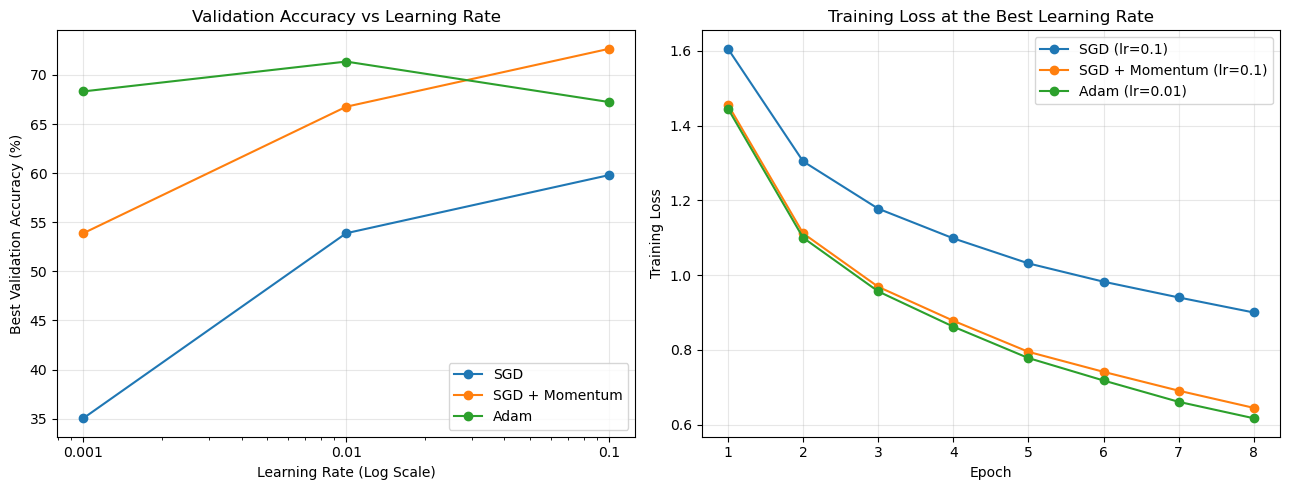

Optimizer               LR    Final Loss   Best Val Acc
-------------------------------------------------------
SGD                  0.001        1.8572         35.04%
SGD                   0.01        1.2885         53.88%
SGD                    0.1        0.8999         59.80%
-------------------------------------------------------
SGD + Momentum       0.001        1.2819         53.88%
SGD + Momentum        0.01        0.8670         66.76%
SGD + Momentum         0.1        0.6446         72.66%
-------------------------------------------------------
Adam                 0.001        0.7864         68.32%
Adam                  0.01        0.6168         71.36%
Adam                   0.1        0.8472         67.24%
-------------------------------------------------------

Optimizer            Best LR   Best Acc   Worst Acc    Spread
SGD                      0.1     59.80%      35.04%    24.76%
SGD + Momentum           0.1     72.66%      53.88%    18.78%
Adam                    0.01 

In [17]:
import torch.nn as nn
import matplotlib.pyplot as plt


# 1. Use the GPU if there is one, the runs below are too slow on CPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

class SmallCNN(nn.Module):
    """A small CNN with batch norm. Three conv stages, then global average pooling."""
    
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),                                    # 32x32 -> 16x16
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.MaxPool2d(2),                                    # 16x16 -> 8x8
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            nn.AdaptiveAvgPool2d(1),                            # 8x8 -> 1x1
        )
        self.classifier = nn.Linear(128, num_classes)
    
    def forward(self, x):
        out = self.features(x)
        return self.classifier(out.flatten(1))

# 2. One full training run with a given optimizer and learning rate
def train_model(optimizer_name, learning_rate, epochs=8):
    # The same seed every time, so every run starts from the same weights
    set_seed(42)
    model = SmallCNN().to(device)
    criterion = nn.CrossEntropyLoss()
    
    # We use our own optimizers from (a), which we already showed match PyTorch
    builders = {
        'SGD':            lambda p: MySGD(p, lr=learning_rate),
        'SGD + Momentum': lambda p: MySGD(p, lr=learning_rate, momentum=0.9),
        'Adam':           lambda p: MyAdam(p, lr=learning_rate),
    }
    optimizer = builders[optimizer_name](model.parameters())
    
    train_losses = []
    val_accuracies = []
    
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0
        batches = 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            batches += 1
        train_losses.append(running_loss / batches)
        
        # Validation accuracy for this epoch
        model.eval()
        correct = 0
        total = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                predictions = model(images).argmax(dim=1)
                correct += (predictions == labels).sum().item()
                total += labels.size(0)
        val_accuracies.append(100 * correct / total)
    
    return train_losses, val_accuracies

# 3. Run every optimizer at three learning rates.
# We use the same three rates for all of them, so the plot shows directly which
# optimizer prefers which range.
learning_rates = [0.001, 0.01, 0.1]
optimizer_names = ['SGD', 'SGD + Momentum', 'Adam']
results = {}

for name in optimizer_names:
    for lr in learning_rates:
        train_losses, val_accuracies = train_model(name, lr)
        results[(name, lr)] = (train_losses, val_accuracies)
        best = max(val_accuracies)
        print(f"{name:<16} lr={lr:<7} final loss={train_losses[-1]:.4f}  best val acc={best:.2f}%")

# 4. Plot validation accuracy against learning rate, and the training loss at the best rate
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = {'SGD': 'tab:blue', 'SGD + Momentum': 'tab:orange', 'Adam': 'tab:green'}

for name in optimizer_names:
    best_accuracies = [max(results[(name, lr)][1]) for lr in learning_rates]
    axes[0].plot(learning_rates, best_accuracies, marker='o', color=colors[name], label=name)

axes[0].set_xscale('log')
axes[0].set_xlabel('Learning Rate (Log Scale)')
axes[0].set_ylabel('Best Validation Accuracy (%)')
axes[0].set_title('Validation Accuracy vs Learning Rate')
axes[0].set_xticks(learning_rates)
axes[0].set_xticklabels([str(lr) for lr in learning_rates])
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# For each optimizer, show the training loss curve of its best learning rate
best_rates = {}
for name in optimizer_names:
    best_lr = max(learning_rates, key=lambda lr: max(results[(name, lr)][1]))
    best_rates[name] = best_lr
    train_losses = results[(name, best_lr)][0]
    axes[1].plot(range(1, len(train_losses) + 1), train_losses, marker='o',
                 color=colors[name], label=f'{name} (lr={best_lr})')

axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Training Loss')
axes[1].set_title('Training Loss at the Best Learning Rate')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

# 5. Table of every run, and how much the accuracy changes across the three rates
print(f"{'Optimizer':<18}{'LR':>8}{'Final Loss':>14}{'Best Val Acc':>15}")
print("-" * 55)
for name in optimizer_names:
    for lr in learning_rates:
        train_losses, val_accuracies = results[(name, lr)]
        print(f"{name:<18}{lr:>8}{train_losses[-1]:>14.4f}{max(val_accuracies):>14.2f}%")
    print("-" * 55)

print(f"\n{'Optimizer':<18}{'Best LR':>10}{'Best Acc':>11}{'Worst Acc':>12}{'Spread':>10}")
for name in optimizer_names:
    accuracies = [max(results[(name, lr)][1]) for lr in learning_rates]
    print(f"{name:<18}{best_rates[name]:>10}{max(accuracies):>10.2f}%{min(accuracies):>11.2f}%{max(accuracies)-min(accuracies):>9.2f}%")

### ***Discussion of Learning Rate Sensitivity***

| Optimizer | lr = 0.001 | lr = 0.01 | lr = 0.1 | Spread |
|---|---|---|---|---|
| SGD | 35.04% | 53.88% | **59.80%** | 24.76% |
| SGD + Momentum | 53.88% | 66.76% | **72.66%** | 18.78% |
| Adam | 68.32% | **71.36%** | 67.24% | 4.12% |

**Adam is by far the least sensitive.** Across two decades of learning rate its accuracy only moves by $4.12\%$, while plain SGD moves by $24.76\%$, about six times more. This is the direct result of the $\sqrt{\hat{v}}$ division we saw in (b): Adam rescales every parameter by the recent size of its own gradient, so the learning rate no longer has to match the scale of the gradients, only set the step size. For plain SGD the learning rate has to do both jobs at once, which is why it is so much harder to choose.

**Adam is the only one whose best rate we actually found.** Its curve rises to a peak at $0.01$ and then falls again at $0.1$, so the optimum is inside our grid. SGD and SGD + Momentum are both still improving at $0.1$, the largest rate we tried, so their true best rate is at or beyond the edge of the grid and the numbers we report for them are a lower bound. This is a real limitation of using only three rates, and we would need to extend the grid upwards to find their peaks.

**Momentum behaves like a $10\times$ larger learning rate.** This is the clearest link back to part (b). The velocity buffer sums the recent gradients, so in steady state the effective step is about $\eta / (1 - \mu) = \eta / 0.1 = 10\eta$. The table confirms it: SGD + Momentum at $0.001$ gives a final training loss of $1.2819$, and plain SGD at $0.01$ gives $1.2885$, almost the same number, and both reach $53.88\%$ validation accuracy. The same pattern holds one decade up, $0.8670$ against $0.8999$. The accuracies drift apart more than the losses do at the higher rates, so this is a rule of thumb about optimization speed rather than an exact equivalence.

**Well tuned SGD with momentum still beats Adam.** The best result overall is SGD + Momentum at $72.66\%$, slightly above Adam's $71.36\%$. This is the usual trade-off in practice: Adam is much easier to tune and gets a good result almost immediately, whereas SGD with momentum needs a search over the learning rate but can end up slightly better. If we only had time for one run, Adam would be the safer choice; if we had time to tune, SGD with momentum would be worth the effort.

**The loss curves.** At each optimizer's best rate, Adam drops the training loss fastest in the first few epochs and also ends the lowest, at $0.6168$ against SGD + Momentum's $0.6446$. Note that this is the opposite order to the validation accuracy, where SGD + Momentum wins ($72.66\%$ against $71.36\%$). So Adam fits the training set better but generalizes slightly worse, which is a pattern often reported for Adam and a good reminder that a lower training loss does not automatically mean a better model. Plain SGD is the slowest at every rate we tried, ending at $0.8999$.

**A caveat on reading these numbers.** Every run uses the same seed and the same 8 epochs, so the comparison between optimizers is fair, but each setting was run only once. Differences of one or two percent are within the noise we would expect from a different seed, so we should only trust the large gaps here, such as Adam's flat curve against SGD's steep one, and not read much into Adam and SGD + Momentum being about one percent apart.